# Assignment 1 — Understanding and assessing `truths.csv`

This notebook examines the Truth Social records in `truths.csv` to
identify data quality issues and determine how they should be handled
before integration with the other project datasets.

We first inspect the structure of the data and check what identifies a
record. We then investigate duplicate records, retruth references,
missing information and timestamp precision. These checks provide the
basis for interpreting posting activity and engagement.

In [75]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path(r"C:\Users\bucco\Desktop\Laboratory of Data Science\project\code_project\data\Project_Data\truths.csv")
df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False,
)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

df_raw.head()

Rows: 1,051,149
Columns: 13


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,703265,2022-05-14 00:00:00,2022-11-01 15:48:16.829245,t,f,2247.0,0,0,0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,108351978111014587,https://truthsocial.com/@jweimer39/posts/10835...,1043583.0
1,807614,2022-03-27 00:00:00,2022-11-23 10:54:36.865046,t,f,20054.0,0,0,0,Enough is enough! RETRUTH,108040697775316106,https://truthsocial.com/@CeceBloomwood/posts/1...,988567.0
2,807615,2022-03-29 00:00:00,2022-11-23 10:55:11.613249,t,f,20054.0,0,0,0,https://justthenews.com/politics-policy/all-th...,108040478595657472,https://truthsocial.com/@CeceBloomwood/posts/1...,1002825.0
3,807618,2022-03-29 00:00:00,2022-11-23 10:56:29.134825,t,f,20054.0,0,0,0,https://t.me/realx22report/6729,108040420546204424,https://truthsocial.com/@CeceBloomwood/posts/1...,989757.0
4,807619,2022-03-29 00:00:00,2022-11-23 10:57:20.028953,f,t,20054.0,0,0,0,@CeceBloomwood,108040224733670356,https://truthsocial.com/@CeceBloomwood/posts/1...,-1.0


## 1. Dataset structure

The dataset contains **1,051,149 rows and 13 columns**:

- **Identifiers:** `id`, `external_id`, `url`.
- **Dates:** `timestamp`, `time_scraped`.
- **Author and post type:** `author`, `is_retruth`, `is_reply`.
- **Engagement:** `like_count`, `retruth_count`, `reply_count`.
- **Content:** `text`, `truth_retruthed`.

All columns are initially loaded as strings to preserve the original values.
We first check duplicates to distinguish the number of rows from the number
of unique records.

In [76]:
exact_duplicates = df_raw.duplicated().sum()

# Remove identical copies only for this check
distinct_rows = df_raw.drop_duplicates()

id_counts = distinct_rows["id"].value_counts()
conflicting_ids = id_counts[id_counts > 1].index

pd.Series({
    "Total rows": len(df_raw),
    "Unique IDs": df_raw["id"].nunique(),
    "Exact duplicate rows (extra copies)": exact_duplicates,
    "IDs with conflicting records": len(conflicting_ids),
}, name="Count").to_frame()

,Count
Total rows,1051149
Unique IDs,1038821
Exact duplicate rows (extra copies),12324
IDs with conflicting records,4


In [77]:
conflicting_records = distinct_rows[
    distinct_rows["id"].isin(conflicting_ids)
]

for post_id, group in conflicting_records.groupby("id", sort=True):
    different_columns = group.columns[
        group.nunique(dropna=False) > 1
    ].tolist()

    print(f"ID: {post_id}")
    print(f"Different columns: {', '.join(different_columns)}")

    display(
        group[["id"] + different_columns]
        .style.set_properties(**{"white-space": "pre-wrap"})
    )

ID: 537119
Different columns: external_id, url, truth_retruthed


,id,external_id,url,truth_retruthed
622080,537119,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts/107927162142169655,1039015.0
766959,537119,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/107949054643865963,-1.0


ID: 683069
Different columns: external_id, url, truth_retruthed


,id,external_id,url,truth_retruthed
740843,683069,108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/108476740611883979,1060937.0
772514,683069,109110717273944816,https://truthsocial.com/@realDonaldTrump/posts/109110717273944816,-1.0


ID: 777869
Different columns: external_id, url, truth_retruthed


,id,external_id,url,truth_retruthed
67135,777869,107949589049761167,https://truthsocial.com/@southerngrl1980/posts/107949589049761167,1056992.0
768217,777869,108301142290305867,https://truthsocial.com/@JackPosobiec/posts/108301142290305867,-1.0


ID: 951819
Different columns: external_id, url, truth_retruthed


,id,external_id,url,truth_retruthed
166203,951819,108476455287288244,https://truthsocial.com/@jrb1954/posts/108476455287288244,1012958.0
763742,951819,109110899592280359,https://truthsocial.com/@realDonaldTrump/posts/109110899592280359,-1.0


In [78]:
# Positive references found in the conflicting records
references = conflicting_records["truth_retruthed"].str.replace(
    r"\.0$", "", regex=True
)
target_ids = references[references.str.fullmatch(r"[1-9]\d*")].unique()

columns = [
    "id", "author", "is_retruth",
    "external_id", "url", "truth_retruthed", "text"
]

targets = distinct_rows[distinct_rows["id"].isin(target_ids)]

print(f"Referenced IDs found: {targets['id'].nunique()} / {len(target_ids)}")

with pd.option_context("display.max_colwidth", 100):
    display(targets[columns])

Referenced IDs found: 0 / 4


,id,author,is_retruth,external_id,url,truth_retruthed,text


### Duplicate findings

We found 12,324 exact duplicate copies and 4 IDs with conflicting records.

For these 4 IDs, only `external_id`, `url` and `truth_retruthed` differ.
Each pair contains one positive retruth reference and one `-1` value.
None of the four referenced IDs is present in this CSV.

In [79]:
# Work without exact copies; keep conflicting versions
df = distinct_rows.copy()

reference = df["truth_retruthed"].str.strip()
normalized_reference = reference.str.replace(r"\.0$", "", regex=True)

reference_status = pd.Series("Other", index=df.index)
reference_status.loc[reference.eq("")] = "Empty"
reference_status.loc[normalized_reference.eq("-1")] = "Sentinel -1"
reference_status.loc[normalized_reference.eq("0")] = "Zero"
reference_status.loc[
    normalized_reference.str.fullmatch(r"[1-9]\d*")
] = "Positive reference"

pd.crosstab(
    df["is_retruth"],
    reference_status,
    rownames=["is_retruth"],
    colnames=["Reference status"],
    margins=True,
)

Reference status,Empty,Positive reference,Sentinel -1,Zero,All
is_retruth,,,,,
f,277911,1,505471,9360,792743
t,0,239255,5,6822,246082
All,277911,239256,505476,16182,1038825


In [80]:
positive_retruths = (
    df["is_retruth"].eq("t")
    & reference_status.eq("Positive reference")
)

retruth_targets = normalized_reference.loc[positive_retruths]
target_found = retruth_targets.isin(df["id"])

reference_check = pd.Series({
    "Target present in CSV": int(target_found.sum()),
    "Target absent from CSV": int((~target_found).sum()),
}).to_frame("Retruth records")

reference_check["Percentage"] = (
    reference_check["Retruth records"]
    .div(len(retruth_targets))
    .mul(100)
    .round(2)
)

display(reference_check)

print(f"Distinct referenced IDs: {retruth_targets.nunique():,}")
print(
    "Distinct referenced IDs absent from CSV: "
    f"{retruth_targets.loc[~target_found].nunique():,}"
)

,Retruth records,Percentage
Target present in CSV,85627,35.79
Target absent from CSV,153628,64.21


Distinct referenced IDs: 100,920
Distinct referenced IDs absent from CSV: 81,026


### Retruth references

Among retruth records with a positive reference, 35.79% point to an ID
present in this CSV, while 64.21% point to an absent ID.

In [81]:
unexpected_reference = df.loc[
    df["is_retruth"].eq("f")
    & reference_status.eq("Positive reference")
]

target_ids = normalized_reference.loc[unexpected_reference.index]

with pd.option_context("display.max_colwidth", 150):
    print("Non-retruth records with a positive reference:")
    display(unexpected_reference.T)

    print("Referenced records found in the CSV:")
    display(df.loc[df["id"].isin(target_ids)].T)

Non-retruth records with a positive reference:


,519946
id,430702
timestamp,2022-03-15 05:47:00
time_scraped,2022-10-14 22:34:56.932013
is_retruth,f
is_reply,f
author,9375.0
like_count,0
retruth_count,0
reply_count,0
text,"""“Ming/Putin” (Klytus/Biden) I''m bored. What plaything can you offer me today?) 430709"


Referenced records found in the CSV:


""
id
timestamp
time_scraped
is_retruth
is_reply
author
like_count
retruth_count
reply_count
text


Record `430702` has several inconsistencies: `is_retruth` is false despite
a positive reference, and both `external_id` and `url` contain dates.
The referenced ID is also absent from the CSV.


In [82]:
external_id = df["external_id"].str.strip()
url = df["url"].str.strip()

external_id_status = pd.Series("Other", index=df.index)
external_id_status.loc[external_id.eq("")] = "Empty"
external_id_status.loc[external_id.str.fullmatch(r"[0-9]+")] = "Numeric"

url_status = pd.Series("Other", index=df.index)
url_status.loc[url.eq("")] = "Empty"
url_status.loc[url.str.fullmatch(r"[0-9]+")] = "Numeric"
url_status.loc[url.str.match(r"(?i)^https?://")] = "HTTP(S)"

pd.crosstab(
    external_id_status,
    url_status,
    rownames=["External ID format"],
    colnames=["URL format"],
    margins=True,
)

URL format,HTTP(S),Numeric,Other,All
External ID format,,,,
Numeric,1021201,47,0,1021248
Other,0,17576,1,17577
All,1021201,17623,1,1038825


In [83]:
anomalous_formats = [
    ("Other", "Numeric"),
    ("Numeric", "Numeric"),
    ("Other", "Other"),
]

columns = [
    "id", "author", "is_retruth",
    "external_id", "url", "truth_retruthed"
]

with pd.option_context("display.max_colwidth", 100):
    for id_format, url_format in anomalous_formats:
        mask = (
            external_id_status.eq(id_format)
            & url_status.eq(url_format)
        )

        print(f"External ID: {id_format} | URL: {url_format}")
        display(df.loc[mask, columns].head(5))

External ID: Other | URL: Numeric


,id,author,is_retruth,external_id,url,truth_retruthed
1165,807653,20054.0,t,CeceBloomwood,107949547160373982,0.0
1166,807654,20054.0,t,CeceBloomwood,107945338731779453,0.0
1167,807655,20054.0,t,CeceBloomwood,107925568586381393,0.0
1168,807656,20054.0,t,CeceBloomwood,107914242452173533,0.0
1169,807657,20054.0,t,CeceBloomwood,107912178895243526,0.0


External ID: Numeric | URL: Numeric


,id,author,is_retruth,external_id,url,truth_retruthed
295192,130246,2923.0,f,1244,108966175235482499,0.0
295194,130250,2923.0,f,1244,108966165367872509,0.0
295196,130257,2923.0,f,1244,108966160218011559,0.0
295200,130273,2923.0,f,1244,108966082767451419,0.0
295203,130278,2923.0,f,1244,108966050533705549,0.0


External ID: Other | URL: Other


,id,author,is_retruth,external_id,url,truth_retruthed
519946,430702,9375.0,f,2022-03-07 07:16:00,2022-10-14 22:35:25.809822,983689.0


In [84]:
pd.crosstab(
    url_status,
    reference_status,
    rownames=["URL format"],
    colnames=["Retruth reference status"],
    margins=True,
)

Retruth reference status,Empty,Positive reference,Sentinel -1,Zero,All
URL format,,,,,
HTTP(S),277911,238836,504454,0,1021201
Numeric,0,419,1022,16182,17623
Other,0,1,0,0,1
All,277911,239256,505476,16182,1038825


### External ID and URL formats

17,623 records contain a numeric value in `url`. In the inspected examples,
`external_id` appears to contain a username rather than a post ID.

All 16,182 zero retruth references occur in this group. However, the group
also contains 419 positive references and 1,022 values of `-1`.

In [85]:
# Extract usernames from standard Truth Social post URLs
url_username = df["url"].str.extract(
    r"(?i)^https?://truthsocial\.com/@([^/?#]+)/posts/[0-9]+/?(?:[?#].*)?$",
    expand=False,
)

known_pairs = pd.DataFrame({
    "author": df["author"].str.strip(),
    "username": url_username.str.casefold(),
})

known_pairs = (
    known_pairs.loc[
        known_pairs["author"].ne("")
        & known_pairs["username"].notna()
    ]
    .drop_duplicates()
)

candidates = df.loc[
    url_status.eq("Numeric"), ["id", "author", "external_id", "url"]
].copy()

candidates["author"] = candidates["author"].str.strip()
candidates["username"] = candidates["external_id"].str.strip().str.casefold()

checked = candidates.merge(
    known_pairs.assign(username_match=True),
    on=["author", "username"],
    how="left",
    validate="many_to_one",
)

checked["check"] = "No matching author–username pair"
checked.loc[
    checked["username_match"].eq(True), "check"
] = "Matching author–username pair"

display(checked["check"].value_counts().to_frame("Records"))

,Records
check,
Matching author–username pair,16918
No matching author–username pair,705


In [86]:
unmatched = checked.loc[
    checked["username_match"].isna()
].copy()

unmatched["reason"] = "Different username observed for this author"

unmatched.loc[
    ~unmatched["author"].isin(known_pairs["author"]),
    "reason",
] = "No standard URL available for this author"

unmatched.loc[
    unmatched["author"].eq(""),
    "reason",
] = "Missing author"

display(unmatched["reason"].value_counts().to_frame("Records"))

for reason, group in unmatched.groupby("reason"):
    print(reason)
    display(group[["id", "author", "external_id", "url"]].head(3))

,Records
reason,
No standard URL available for this author,559
Missing author,145
Different username observed for this author,1


Different username observed for this author


,id,author,external_id,url
3655,894769,21203.0,JackPosobiec,107947130681947614


Missing author


,id,author,external_id,url
3674,895511,,truthtent,108864982160272342
3689,895527,,JackPosobiec,108822381542261053
3698,895535,,JohnPaulMacIsaac,108814846897812544


No standard URL available for this author


,id,author,external_id,url
362,723113,17778.0,MarieYarger,109088327488770457
363,723114,17778.0,MarieYarger,109044375155090322
364,723115,17778.0,MarieYarger,109044370082097330


In [87]:
mismatch = unmatched.loc[
    unmatched["reason"].eq("Different username observed for this author")
]

display(mismatch[["id", "author", "external_id", "url"]])

for author_id in mismatch["author"].unique():
    print(f"Usernames observed for author {author_id}:")
    display(
        known_pairs.loc[known_pairs["author"].eq(author_id)]
    )

    print("Example records with standard URLs:")
    display(
        df.loc[
            df["author"].str.strip().eq(author_id)
            & url_username.notna(),
            ["id", "author", "is_retruth", "external_id",
             "url", "truth_retruthed"],
        ].head(5)
    )

,id,author,external_id,url
3655,894769,21203.0,JackPosobiec,107947130681947614


Usernames observed for author 21203.0:


,author,username
134199,21203.0,jeremyryanslate


Example records with standard URLs:


,id,author,is_retruth,external_id,url,truth_retruthed
134199,894707,21203.0,f,108918484627549435,https://truthsocial.com/@jeremyryanslate/posts...,-1.0
134200,894713,21203.0,f,108886742977898759,https://truthsocial.com/@jeremyryanslate/posts...,-1.0
134201,894714,21203.0,t,108873115714471897,https://truthsocial.com/@jeremyryanslate/posts...,894714.0
134202,894717,21203.0,t,108857087249031454,https://truthsocial.com/@jeremyryanslate/posts...,894717.0
134203,894719,21203.0,f,108847220240609499,https://truthsocial.com/@jeremyryanslate/posts...,-1.0


In [88]:
missing_summary = []

for column in df.columns:
    values = df[column].str.strip()

    empty = values.eq("")
    possible_marker = values.str.casefold().isin(
        ["na", "n/a", "nan", "null", "none"]
    )

    missing_summary.append({
        "Column": column,
        "Empty": int(empty.sum()),
        "Empty (%)": round(empty.mean() * 100, 2),
        "Possible missing markers": int(possible_marker.sum()),
    })

pd.DataFrame(missing_summary).set_index("Column")

,Empty,Empty (%),Possible missing markers
Column,,,
id,0,0.00,0
timestamp,0,0.00,0
time_scraped,0,0.00,0
is_retruth,0,0.00,0
is_reply,0,0.00,0
author,145,0.01,0
like_count,0,0.00,0
retruth_count,0,0.00,0
reply_count,0,0.00,0


In [89]:
text = df["text"].str.strip()

possible_text_marker = text.str.casefold().isin(
    ["na", "n/a", "nan", "null", "none"]
)

print("Possible missing markers in text:")
display(
    df.loc[
        possible_text_marker,
        ["id", "text", "author", "is_retruth", "url"],
    ]
)

print("Records with empty text:")
display(
    pd.crosstab(
        df.loc[text.eq(""), "is_retruth"],
        reference_status.loc[text.eq("")],
        rownames=["is_retruth"],
        colnames=["Reference status"],
        margins=True,
    )
)

Possible missing markers in text:


,id,text,author,is_retruth,url
129632,887272,None,21083.0,f,https://truthsocial.com/@Anniebiebs5/posts/108...
263868,89018,None,1549.0,f,https://truthsocial.com/@angelajwood/posts/108...


Records with empty text:


Reference status,Empty,Zero,All
is_retruth,,,
f,2,51,53
t,0,123,123
All,2,174,176


### Missing text

176 records have empty text; 174 also have a zero retruth reference
and a numeric URL. All 123 retruths with empty text lack a usable
reference to the original post.

Two additional records contain the literal string `"None"`, which we
preserve because its meaning is uncertain. Empty-text records are
retained pending checks against the media dataset.

In [90]:
text_quality = pd.Series("Other non-empty text", index=df.index)

text_quality.loc[text.eq("")] = "Empty"
text_quality.loc[text.eq("None")] = 'Literal "None"'
text_quality.loc[text.eq("<")] = 'Single "<"'

text_summary = text_quality.value_counts().to_frame("Records")
text_summary["Percentage"] = (
    text_summary["Records"].div(len(df)).mul(100).round(2)
)

display(text_summary)

,Records,Percentage
Other non-empty text,1033224,99.46
"Single ""<""",5423,0.52
Empty,176,0.02
"Literal ""None""",2,0.00


In [91]:
date_profiles = {}

for column in ["timestamp", "time_scraped"]:
    values = df[column].str.strip()

    status = pd.Series("Other format", index=df.index)

    status.loc[values.eq("")] = "Empty"

    status.loc[
        values.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
    ] = "Date only"

    status.loc[
        values.str.fullmatch(
            r"\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}(?:\.\d+)?"
        )
    ] = "Date and time"

    status.loc[
        values.str.fullmatch(
            r"\d{4}-\d{2}-\d{2}[ T]00:00:00(?:\.0+)?"
        )
    ] = "Explicit midnight"

    date_profiles[column] = status

pd.DataFrame({
    column: status.value_counts()
    for column, status in date_profiles.items()
}).fillna(0).astype(int)

,timestamp,time_scraped
Date and time,819140,760914
Date only,918,0
Explicit midnight,218767,277911


In [92]:
dates = pd.DataFrame({
    column: pd.to_datetime(
        df[column].str.strip(),
        format="ISO8601",
        errors="coerce",
    )
    for column in ["timestamp", "time_scraped"]
})

display(pd.DataFrame({
    "Invalid dates": dates.isna().sum(),
    "Earliest": dates.min(),
    "Latest": dates.max(),
}))

valid_dates = dates.notna().all(axis=1)

scraped_before = (
    valid_dates
    & dates["time_scraped"].lt(dates["timestamp"])
)

same_day = (
    dates["time_scraped"].dt.normalize()
    .eq(dates["timestamp"].dt.normalize())
)

display(pd.Series({
    "Scraped before publication, same day":
        int((scraped_before & same_day).sum()),
    "Scraped on an earlier day":
        int((scraped_before & ~same_day).sum()),
}, name="Records").to_frame())

,Invalid dates,Earliest,Latest
timestamp,0,2022-02-07 23:31:00.000000,2024-10-29 21:24:00
time_scraped,0,2022-09-14 17:27:42.677694,2024-10-29 00:00:00


,Records
"Scraped before publication, same day",62239
Scraped on an earlier day,0


In [93]:
pd.crosstab(
    date_profiles["time_scraped"].loc[scraped_before],
    same_day.loc[scraped_before],
    rownames=["Scraping timestamp format"],
    colnames=["Same day as publication"],
    margins=True,
)

Same day as publication,True,All
Scraping timestamp format,,
Explicit midnight,62239,62239
All,62239,62239


### Timestamp quality

All dates are parseable. Publication dates range from February 2022
to October 2024.

In 62,239 records, scraping appears earlier than publication, but always
at midnight on the same day. This suggests limited time precision rather
than a clear chronological error. We retain the values without imputing times.

Publication timestamps also include 918 date-only values and 218,767
midnight values. 

Months with no records:
[]


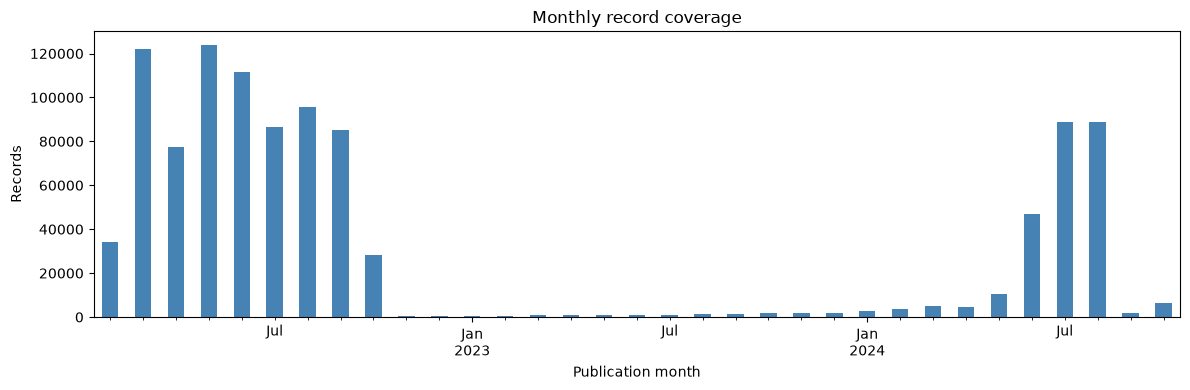

In [94]:
monthly_records = (
    dates["timestamp"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

# Include months with no records
all_months = pd.period_range(
    monthly_records.index.min(),
    monthly_records.index.max(),
    freq="M",
)

monthly_records = monthly_records.reindex(all_months, fill_value=0)

ax = monthly_records.plot.bar(
    figsize=(12, 4),
    color="steelblue",
    title="Monthly record coverage",
)

ax.set_xlabel("Publication month")
ax.set_ylabel("Records")
ax.figure.tight_layout()

print("Months with no records:")
print(monthly_records[monthly_records.eq(0)].index.astype(str).tolist())

In [95]:
yearly_profile = pd.DataFrame({
    "year": dates["timestamp"].dt.year,
    "Numeric URL (%)": url_status.eq("Numeric"),
    "Empty retruth reference (%)": reference_status.eq("Empty"),
    "Publication at midnight (%)":
        date_profiles["timestamp"].eq("Explicit midnight"),
    "Scraping at midnight (%)":
        date_profiles["time_scraped"].eq("Explicit midnight"),
})

grouped = yearly_profile.groupby("year")

yearly_summary = grouped.mean().mul(100).round(2)
yearly_summary.insert(0, "Records", grouped.size())

display(yearly_summary)

,Records,Numeric URL (%),Empty retruth reference (%),Publication at midnight (%),Scraping at midnight (%)
year,,,,,
2022,765713,2.3,0.63,28.54,0.63
2023,13960,0.0,100.00,0.10,100.00
2024,259152,0.0,100.00,0.08,100.00


In [96]:
engagement_columns = ["like_count", "retruth_count", "reply_count"]

engagement = df[engagement_columns].apply(
    pd.to_numeric, errors="coerce"
)

engagement_checks = pd.DataFrame({
    "Not numeric / missing": engagement.isna().sum(),
    "Negative": engagement.lt(0).sum(),
    "Non-integer": (
        engagement.notna() & engagement.mod(1).ne(0)
    ).sum(),
})

display(engagement_checks)

,Not numeric / missing,Negative,Non-integer
like_count,0,0,0
retruth_count,0,0,0
reply_count,0,0,0


In [97]:
engagement_summary = engagement.describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T

engagement_summary["Zero (%)"] = (
    engagement.eq(0).mean().mul(100)
)

display(
    engagement_summary[
        ["min", "50%", "mean", "90%", "95%", "99%", "max", "Zero (%)"]
    ].round(2)
)

,min,50%,mean,90%,95%,99%,max,Zero (%)
like_count,0.0,1.0,24.45,15.0,61.0,402.52,31340.0,35.92
retruth_count,0.0,0.0,9.42,7.0,25.0,158.0,12183.0,70.35
reply_count,0.0,0.0,3.19,3.0,8.0,55.0,7137.0,54.1


In [98]:
top_likes = engagement["like_count"].nlargest(10).index

columns = [
    "id", "author", "is_retruth", "truth_retruthed",
    "like_count", "retruth_count", "reply_count",
    "external_id", "url", "text",
]

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
):
    display(df.loc[top_likes, columns])

,id,author,is_retruth,truth_retruthed,like_count,retruth_count,reply_count,external_id,url,text
245702,69023,96.0,t,0.0,31340,12183,7137,MercedesSchlapp,108227743321071998,I’M BACK! #COVFEFE
291389,125307,2885.0,t,0.0,31340,12183,7137,ladylarry,108211846802091586,I’M BACK! #COVFEFE
295266,130407,2882.0,t,0.0,31340,12183,7137,tori96,108222311998023674,I’M BACK! #COVFEFE
486328,366255,5078.0,t,0.0,31340,12183,7137,mikehamilton,108212138991850505,I’M BACK! #COVFEFE
486731,366931,8235.0,t,0.0,31340,12183,7137,slovakjoey,108212728322714077,I’M BACK! #COVFEFE
525455,413805,8768.0,t,0.0,31340,12183,7137,HollyMae,108212741025939008,I’M BACK! #COVFEFE
534582,424756,9318.0,t,0.0,31340,12183,7137,jodijanell,108212601795439749,I’M BACK! #COVFEFE
605328,510621,10426.0,t,0.0,31340,12183,7137,GannCro,108213245533474904,I’M BACK! #COVFEFE
1166,807654,20054.0,t,0.0,22069,5835,4562,CeceBloomwood,107945338731779453,Get Ready! Your favorite President will see you soon!
44305,754447,19573.0,t,0.0,22069,5862,4582,aligarabedian,107816668702402071,Get Ready! Your favorite President will see you soon!


In [99]:
retruth_mask = df["is_retruth"].eq("t")

retruth_engagement = engagement.loc[retruth_mask].copy()
retruth_engagement["Reference status"] = reference_status.loc[retruth_mask]
retruth_engagement["Has engagement"] = (
    engagement.loc[retruth_mask].gt(0).any(axis=1)
)

summary = retruth_engagement.groupby("Reference status").agg(
    Records=("Has engagement", "size"),
    With_engagement=("Has engagement", "sum"),
    Median_likes=("like_count", "median"),
    Max_likes=("like_count", "max"),
)

summary["With engagement (%)"] = (
    summary["With_engagement"].div(summary["Records"]).mul(100).round(2)
)

display(summary)

,Records,With_engagement,Median_likes,Max_likes,With engagement (%)
Reference status,,,,,
Positive reference,239255,187,0.0,1533,0.08
Sentinel -1,5,3,98.0,1533,60.0
Zero,6822,5572,127.5,31340,81.68


Non-zero engagement occurs in 81.68% of retruths with a zero reference,
compared with 0.08% of those with a positive reference.

Together with the URL anomalies and repeated counters, this suggests
different representations of retruth records. Engagement totals should
not be interpreted as counts of distinct events.

In [100]:
positive_with_engagement = (
    df["is_retruth"].eq("t")
    & reference_status.eq("Positive reference")
    & engagement.gt(0).any(axis=1)
)

example_indices = (
    engagement.loc[positive_with_engagement, "like_count"]
    .nlargest(5)
    .index
)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
):
    display(df.loc[
        example_indices,
        [
            "id", "author", "truth_retruthed",
            "like_count", "retruth_count", "reply_count",
            "external_id", "url", "text",
        ],
    ])

,id,author,truth_retruthed,like_count,retruth_count,reply_count,external_id,url,text
740843,683069,2780.0,1060937.0,1533,570,167,108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/108476740611883979,"“National Bourbon Day, Flag Day, President Trump’s birthday, AND U.S. Army Birthday. The day jus..."
67673,778415,7060.0,978191.0,1060,609,104,KnockKnock,108823814652664902,Obama and Hillary were running guns from Libyan jihadists to Syrian jihadists and when they got ...
67135,777869,19822.0,1056992.0,603,336,59,107949589049761167,https://truthsocial.com/@southerngrl1980/posts/107949589049761167,"TRUMP: “Before we can defeat the Democrats, Socialists, and Communists at the ballot box this fa..."
67670,778461,7060.0,978709.0,526,309,35,KnockKnock,107983954246679330,Just so you know ... these are the same exact weasels who call you a Putin Puppet if you don't b...
67667,778457,7060.0,978600.0,485,378,35,KnockKnock,108058091937541813,"WISCONSIN'S ELECTION WAS DECIDED BY 20,682 VOTES!!! THEY TRAFFICKED 137,551!!! RIGGED ELECTION!!!"


In [101]:
flag_columns = ["is_retruth", "is_reply"]

print("Flag values:")
display(pd.DataFrame({
    column: df[column].value_counts(dropna=False)
    for column in flag_columns
}).fillna(0).astype(int))

print("Flag combinations:")
display(pd.crosstab(
    df["is_retruth"],
    df["is_reply"],
    rownames=["is_retruth"],
    colnames=["is_reply"],
    margins=True,
))

Flag values:


,is_retruth,is_reply
f,792743,751685
t,246082,287140


Flag combinations:


is_reply,f,t,All
is_retruth,,,
f,505753,286990,792743
t,245932,150,246082
All,751685,287140,1038825


In [102]:
identifier_checks = []

for column in ["id", "author"]:
    values = df[column].str.strip()

    empty = values.eq("")
    positive_integer = values.str.fullmatch(r"[1-9]\d*(?:\.0+)?")

    identifier_checks.append({
        "Column": column,
        "Empty": int(empty.sum()),
        "Positive integer format": int(positive_integer.sum()),
        "Other format": int((~empty & ~positive_integer).sum()),
    })

display(pd.DataFrame(identifier_checks).set_index("Column"))

,Empty,Positive integer format,Other format
Column,,,
id,0,1038825,0
author,145,1038680,0


In [103]:
url_post_id = df["url"].str.strip().str.extract(
    r"(?i)^https?://truthsocial\.com/@[^/?#]+/posts/([0-9]+)/?(?:[?#].*)?$",
    expand=False,
)

http_url = url_status.eq("HTTP(S)")
recognized_url = http_url & url_post_id.notna()

id_matches = url_post_id.eq(
    df["external_id"].str.strip()
).fillna(False)

display(pd.Series({
    "Recognized URL, matching external ID":
        int((recognized_url & id_matches).sum()),
    "Recognized URL, different external ID":
        int((recognized_url & ~id_matches).sum()),
    "HTTP(S) URL with another structure":
        int((http_url & ~recognized_url).sum()),
}, name="Records").to_frame())

display(df.loc[
    http_url & (~recognized_url | ~id_matches),
    ["id", "external_id", "url"],
].head(10))

,Records
"Recognized URL, matching external ID",1021201
"Recognized URL, different external ID",0
HTTP(S) URL with another structure,0


,id,external_id,url


All 1,021,201 HTTP(S) URLs match the expected post URL structure,
and their post IDs agree with `external_id`. 

In [104]:
text_features = pd.DataFrame(index=df.index)

# Exclude empty text and the two special cases already inspected
usable_text = ~text.isin(["", "<", "None"])

text_features["usable_text"] = usable_text
text_features["text_length"] = text.str.len().where(usable_text)

patterns = {
    "has_hashtag": r"(?<!\w)#\w+",
    "has_mention": r"(?<!\w)@\w+",
    "has_link": r"(?i)https?://\S+",
    "has_emoji_marker": r"<emoji:\s*[^>]+>",
}

for feature, pattern in patterns.items():
    text_features[feature] = (
        text.str.contains(pattern, regex=True)
        .where(usable_text)
        .astype("boolean")
    )

feature_summary = pd.DataFrame({
    "Records": text_features[list(patterns)].sum(),
    "Usable texts (%)": (
        text_features[list(patterns)].mean().mul(100).round(2)
    ),
})

display(feature_summary)
display(
    text_features["text_length"]
    .describe(percentiles=[0.50, 0.90, 0.99])
    .round(2)
)

,Records,Usable texts (%)
has_hashtag,337471,32.66
has_mention,96401,9.33
has_link,269676,26.1
has_emoji_marker,239648,23.19


count    1033224.0
mean        216.65
std         326.03
min            1.0
50%          126.0
90%          492.0
99%        1114.77
max        13498.0
Name: text_length, dtype: Float64

In [105]:
longest_indices = text_features["text_length"].nlargest(3).index

display(
    df.loc[longest_indices, ["id", "is_retruth", "external_id"]]
    .assign(text_length=text_features.loc[longest_indices, "text_length"])
)

for index in longest_indices:
    content = df.at[index, "text"]

    print(f"\nID: {df.at[index, 'id']} | Characters: {len(content):,}")
    print("START:")
    print(content[:1200])
    print("\nEND:")
    print(content[-500:])

,id,is_retruth,external_id,text_length
657900,580351,f,108330765012432743,13498
474106,427814,f,107879253867290451,12786
1040097,2315207,f,113045278007939425,12741



ID: 580351 | Characters: 13,498
START:
<emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: joy><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: joy><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: joy> <emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: rolling_on_the_floor_laughing><emoji: joy><emoji: joy><emoji: rolling_on_the_floor_laughing><em

In [106]:
text_format = pd.DataFrame(index=df.index)

text_format["HTML-like tags"] = text.str.contains(
    r"</?[A-Za-z][A-Za-z0-9-]*(?:\s[^<>]*|\s*/?)>",
    regex=True,
)

text_format["Emoji markers"] = text.str.contains(
    r"<emoji:\s*[^>]+>",
    regex=True,
)

text_format["HTML entities"] = text.str.contains(
    r"&(?:[A-Za-z][A-Za-z0-9]+|#\d+|#x[0-9A-Fa-f]+);",
    regex=True,
)

display(pd.DataFrame({
    "Records": text_format.sum(),
    "Records (%)": text_format.mean().mul(100).round(2),
}))

display(
    text_format.groupby(dates["timestamp"].dt.year)
    .mean()
    .mul(100)
    .round(2)
)

,Records,Records (%)
HTML-like tags,11338,1.09
Emoji markers,239648,23.07
HTML entities,12948,1.25


,HTML-like tags,Emoji markers,HTML entities
timestamp,,,
2022,0.07,21.49,0.25
2023,4.57,30.23,1.29
2024,3.91,27.34,4.19


In [107]:
html_examples = (
    text_features.loc[
        text_format["HTML-like tags"], "text_length"
    ]
    .dropna()
    .sort_values()
)

# Inspect short examples that still contain some content
example_indices = html_examples[
    html_examples.between(80, 500)
].head(3).index

for index in example_indices:
    print(f"\nID: {df.at[index, 'id']}")
    print(df.at[index, "text"])


ID: 2336714
<span class="h-card">https://truthsocial.com/@MTG" class="u-url mention status-link</span>

ID: 2335441
<span class="h-card">https://truthsocial.com/@hooksies" class="u-url mention status-link</span>

ID: 2338303
<span class="h-card">https://truthsocial.com/@Kblazer7" class="u-url mention status-link</span>


In [108]:
status_link_residue = df["text"].str.contains(
    r"""["']\s+class=["']u-url\s+mention\s+status-link""",
    regex=True,
    na=False,
)

print(f"Records with this pattern: {status_link_residue.sum():,}")

display(
    pd.crosstab(
        dates["timestamp"].dt.year,
        status_link_residue,
        rownames=["Year"],
        colnames=["Status-link residue"],
    )
)

print("Further examples:")
for index in df.index[status_link_residue][:3]:
    print(f"\nID: {df.at[index, 'id']}")
    print(df.at[index, "text"][:600])

Records with this pattern: 9,879


Status-link residue,False,True
Year,,
2022,765161,552
2023,13576,384
2024,250209,8943


Further examples:

ID: 1061836
Happy Birthday Mr. President. America loves <span class="h-card">https://truthsocial.com/@realDonaldTrump" class="u-url mention status-link</span>. #DJT Best President Ever. Period.  #June14 #FlagDay #Truth #Trump2024 #MAGA2024 #TakeAmericaBack #XTeam #LilyPadLounge #TheHashTagChat #AdjunctProfessor

ID: 1061877
HAPPY BIRTHDAY  @realDonaldTrump  We love you❗️ #Trump2024  #XTeam  #TheHashTagChat  #LilyPadLounge    @Trumpspatriots24  @AdjunctProfessor @SgtPepper @HeyJude88  @rojas @DonnaHawk @JereMemez @theboops @LarryL167 <span class="h-card">https://truthsocial.com/@Faith_4America" class="u-url mention status-link</span>  <span class="h-card">https://truthsocial.com/@sc_maga" class="u-url mention status-link</span>  <span class="h-card">https://truthsocial.com/@PatriotGrandmom" class="u-url mention status-link</span>  <span class="h-card">https://truthsocial.com/@BShanks" class="u-url mention status-l

ID: 1062073
Happy Birthday Mr. President. America lov

In [109]:
quality_flags = pd.DataFrame({
    "conflicting_id": df["id"].isin(conflicting_ids),
    "missing_author": df["author"].str.strip().eq(""),
    "empty_text": text.eq(""),
    "text_only_angle_bracket": text.eq("<"),
    "text_literal_none": text.eq("None"),
    "numeric_url": url_status.eq("Numeric"),
    "malformed_status_link": status_link_residue,
    "publication_date_only":
        date_profiles["timestamp"].eq("Date only"),
    "publication_at_midnight":
        date_profiles["timestamp"].eq("Explicit midnight"),
    "retruthed_target_absent": (
        df["is_retruth"].eq("t")
        & reference_status.eq("Positive reference")
        & ~normalized_reference.isin(df["id"])
    ),
}, index=df.index)

display(
    quality_flags.sum()
    .sort_values(ascending=False)
    .to_frame("Flagged records")
)

,Flagged records
publication_at_midnight,218767
retruthed_target_absent,153628
numeric_url,17623
malformed_status_link,9879
text_only_angle_bracket,5423
publication_date_only,918
empty_text,176
missing_author,145
conflicting_id,8
text_literal_none,2


In [110]:
quality_flags["non_retruth_with_positive_reference"] = (
    df["is_retruth"].eq("f")
    & reference_status.eq("Positive reference")
)

quality_flags["retruth_without_usable_reference"] = (
    df["is_retruth"].eq("t")
    & ~reference_status.eq("Positive reference")
)

quality_flags["other_url_format"] = url_status.eq("Other")

quality_flags["scraping_at_midnight"] = (
    date_profiles["time_scraped"].eq("Explicit midnight")
)

quality_flags["scraped_before_publication"] = scraped_before

display(
    quality_flags.sum()
    .sort_values(ascending=False)
    .to_frame("Flagged records")
)

,Flagged records
scraping_at_midnight,277911
publication_at_midnight,218767
retruthed_target_absent,153628
scraped_before_publication,62239
numeric_url,17623
malformed_status_link,9879
retruth_without_usable_reference,6827
text_only_angle_bracket,5423
publication_date_only,918
empty_text,176


In [111]:
retruth_links = df.loc[
    positive_retruths, ["id", "truth_retruthed"]
].copy()

retruth_links["target_id"] = normalized_reference.loc[positive_retruths]

# Exact copies have already been removed
records_per_id = df["id"].value_counts()

retruth_links["target_records"] = (
    retruth_links["target_id"]
    .map(records_per_id)
    .fillna(0)
    .astype(int)
)

retruth_links["self_reference"] = (
    retruth_links["id"].eq(retruth_links["target_id"])
)

display(pd.Series({
    "Target absent":
        retruth_links["target_records"].eq(0).sum(),
    "Target has one record":
        retruth_links["target_records"].eq(1).sum(),
    "Target has conflicting versions":
        retruth_links["target_records"].gt(1).sum(),
    "Self-reference":
        retruth_links["self_reference"].sum(),
}, name="Retruth records").to_frame())

print("Self-reference examples:")
display(
    retruth_links.loc[retruth_links["self_reference"]].head(10)
)

,Retruth records
Target absent,153628
Target has one record,85627
Target has conflicting versions,0
Self-reference,6133


Self-reference examples:


,id,truth_retruthed,target_id,target_records,self_reference
14,703305,703305.0,703305,1,True
22,703328,703328.0,703328,1,True
29,703395,703395.0,703395,1,True
34,703287,703287.0,703287,1,True
43,703330,703330.0,703330,1,True
119,703402,703402.0,703402,1,True
168,703476,703476.0,703476,1,True
181,703442,703442.0,703442,1,True
184,703450,703450.0,703450,1,True
231,703522,703522.0,703522,1,True


In [112]:
quality_flags["self_reference"] = (
    df["is_retruth"].eq("t")
    & reference_status.eq("Positive reference")
    & df["id"].eq(normalized_reference)
)

valid_links = retruth_links.loc[
    retruth_links["target_records"].eq(1)
    & ~retruth_links["self_reference"],
    ["id", "target_id"],
]

target_columns = [
    "id", "is_retruth", "is_reply", "text", "timestamp"
]

unique_targets = df.loc[
    ~df["id"].duplicated(keep=False), target_columns
].rename(columns={
    column: f"target_{column}"
    for column in target_columns
})

linked_retruths = valid_links.merge(
    unique_targets,
    on="target_id",
    how="left",
    validate="many_to_one",
)

display(pd.crosstab(
    linked_retruths["target_is_retruth"],
    linked_retruths["target_is_reply"],
    rownames=["Target is retruth"],
    colnames=["Target is reply"],
    margins=True,
))

Target is reply,f,t,All
Target is retruth,,,
f,72417,126,72543
t,6951,0,6951
All,79368,126,79494


In [113]:
source_texts = df.loc[
    positive_retruths, ["id", "text"]
].rename(columns={"text": "source_text"})

text_comparison = linked_retruths.merge(
    source_texts,
    on="id",
    how="left",
    validate="one_to_one",
)

source = text_comparison["source_text"].str.strip()
target = text_comparison["target_text"].str.strip()

comparable = (
    ~source.isin(["", "<", "None"])
    & ~target.isin(["", "<", "None"])
)

text_comparison["text_check"] = "Uninformative text on either side"
text_comparison.loc[
    comparable & source.eq(target), "text_check"
] = "Same text"
text_comparison.loc[
    comparable & source.ne(target), "text_check"
] = "Different text"

display(
    text_comparison["text_check"]
    .value_counts()
    .to_frame("Links")
)

display(
    text_comparison.loc[
        text_comparison["text_check"].eq("Different text"),
        ["id", "target_id", "source_text", "target_text"],
    ].head(5)
)

,Links
text_check,
Same text,79494


,id,target_id,source_text,target_text


In [114]:
source_dates = df.loc[positive_retruths, ["id"]].copy()
source_dates["source_timestamp"] = dates.loc[
    positive_retruths, "timestamp"
]

date_comparison = linked_retruths.merge(
    source_dates,
    on="id",
    how="left",
    validate="one_to_one",
)

target_time = pd.to_datetime(
    date_comparison["target_timestamp"],
    format="ISO8601",
    errors="coerce",
)
source_time = date_comparison["source_timestamp"]

date_comparison["time_check"] = "Same timestamp"

date_comparison.loc[
    source_time.gt(target_time), "time_check"
] = "Retruth later than target"

date_comparison.loc[
    source_time.lt(target_time), "time_check"
] = "Retruth earlier than target"

display(
    date_comparison["time_check"]
    .value_counts()
    .to_frame("Links")
)

display(
    date_comparison.loc[
        source_time.lt(target_time),
        ["id", "target_id", "source_timestamp", "target_timestamp"],
    ].head(5)
)

,Links
time_check,
Same timestamp,59905
Retruth earlier than target,10935
Retruth later than target,8654


,id,target_id,source_timestamp,target_timestamp
0,703369,2623,2022-05-22,2022-05-22 12:12:00
1,703371,2622,2022-05-22,2022-05-22 12:14:00
2,703386,1926,2022-08-18,2022-08-18 12:12:00
3,703403,80455,2022-05-21,2022-05-21 10:56:00
5,703427,15085,2022-05-21,2022-05-21 23:03:00


In [115]:
earlier = source_time.lt(target_time)

same_calendar_day = (
    source_time.dt.normalize()
    .eq(target_time.dt.normalize())
)

source_at_midnight = source_time.eq(
    source_time.dt.normalize()
)

display(pd.Series({
    "Earlier on the same day, source at midnight":
        int((earlier & same_calendar_day & source_at_midnight).sum()),
    "Earlier on the same day, source at another time":
        int((earlier & same_calendar_day & ~source_at_midnight).sum()),
    "Earlier calendar day":
        int((earlier & ~same_calendar_day).sum()),
}, name="Links").to_frame())

print("Examples from earlier calendar days:")
display(
    date_comparison.loc[
        earlier & ~same_calendar_day,
        ["id", "target_id", "source_timestamp", "target_timestamp"],
    ].head(10)
)

,Links
"Earlier on the same day, source at midnight",8096
"Earlier on the same day, source at another time",690
Earlier calendar day,2149


Examples from earlier calendar days:


,id,target_id,source_timestamp,target_timestamp
23,703875,118788,2022-06-05,2022-09-10 11:32:00
39,704020,813787,2022-06-04,2022-08-14 00:00:00
60,704081,15044,2022-05-29,2022-06-16 15:46:00
78,704235,66270,2022-05-25,2022-05-26 02:14:00
102,704993,16549,2022-05-31,2022-08-11 06:46:00
105,705078,15044,2022-05-29,2022-06-16 15:46:00
183,707532,66401,2022-03-24,2022-03-25 02:24:00
254,708320,837043,2022-03-14,2022-03-15 00:00:00
265,708615,901337,2022-05-31,2022-10-06 00:00:00
282,708590,66257,2022-06-08,2022-06-09 03:19:00


In [116]:
date_comparison["chronology"] = "Same timestamp"

date_comparison.loc[
    source_time.gt(target_time), "chronology"
] = "Later"

date_comparison.loc[
    earlier & same_calendar_day, "chronology"
] = "Earlier, same day"

date_comparison.loc[
    earlier & ~same_calendar_day, "chronology"
] = "Earlier calendar day"

display(pd.crosstab(
    date_comparison["chronology"],
    date_comparison["target_is_retruth"],
    rownames=["Source relative to target"],
    colnames=["Target is retruth"],
    margins=True,
))

Target is retruth,f,t,All
Source relative to target,,,
Earlier calendar day,2103,46,2149
"Earlier, same day",7790,996,8786
Later,8313,341,8654
Same timestamp,54337,5568,59905
All,72543,6951,79494


### Retruth link consistency

All 79,494 non-self links with an available target have matching text.
However, 2,149 source records precede their targets by calendar date;
2,103 of these targets are marked as non-retruths.

In [117]:
earlier_day_ids = date_comparison.loc[
    date_comparison["chronology"].eq("Earlier calendar day"),
    "id",
]

target_retruth_ids = linked_retruths.loc[
    linked_retruths["target_is_retruth"].eq("t"),
    "id",
]

quality_flags["retruth_before_target_day"] = df["id"].isin(
    earlier_day_ids
)

quality_flags["target_is_retruth"] = df["id"].isin(
    target_retruth_ids
)

display(
    quality_flags[
        [
            "self_reference",
            "retruthed_target_absent",
            "retruth_before_target_day",
            "target_is_retruth",
        ]
    ].sum().to_frame("Flagged records")
)

,Flagged records
self_reference,6133
retruthed_target_absent,153628
retruth_before_target_day,2149
target_is_retruth,6951


In [118]:
# Count how many distinct authors are associated with each username
authors_per_username = known_pairs.groupby("username")["author"].nunique()

unique_usernames = authors_per_username[
    authors_per_username.eq(1)
].index

username_to_author = (
    known_pairs.loc[known_pairs["username"].isin(unique_usernames)]
    .set_index("username")["author"]
)

missing_authors = df.loc[
    df["author"].str.strip().eq(""),
    ["id", "external_id", "url", "is_retruth"],
].copy()

missing_authors["candidate_username"] = (
    missing_authors["external_id"].str.strip().str.casefold()
)

missing_authors["matching_authors"] = (
    missing_authors["candidate_username"]
    .map(authors_per_username)
    .fillna(0)
    .astype(int)
)

missing_authors["candidate_author"] = (
    missing_authors["candidate_username"].map(username_to_author)
)

display(pd.Series({
    "Unique author candidate":
        missing_authors["matching_authors"].eq(1).sum(),
    "Multiple author candidates":
        missing_authors["matching_authors"].gt(1).sum(),
    "No candidate":
        missing_authors["matching_authors"].eq(0).sum(),
}, name="Records").to_frame())

display(missing_authors.head(10))

,Records
Unique author candidate,58
Multiple author candidates,18
No candidate,69


,id,external_id,url,is_retruth,candidate_username,matching_authors,candidate_author
134639,895511,truthtent,108864982160272342,f,truthtent,0,<NA>
134654,895527,JackPosobiec,108822381542261053,f,jackposobiec,3,<NA>
134663,895535,JohnPaulMacIsaac,108814846897812544,f,johnpaulmacisaac,0,<NA>
134664,895536,Lara45,109073924301696705,f,lara45,0,<NA>
134679,895573,JackPosobiec,108639442992116282,f,jackposobiec,3,<NA>
134683,895587,MelaniaTrump,109027164115408705,f,melaniatrump,1,559.0
134686,895595,NewsMax,109017355982286163,f,newsmax,1,145.0
134692,895553,DonaldJTrumpJr,108712395933363004,f,donaldjtrumpjr,1,300.0
135661,897718,doug4gov,109105436245928682,f,doug4gov,0,<NA>
136412,899018,PepeLivesMatter,107922117579592120,f,pepelivesmatter,1,1343.0


In [119]:
ambiguous_usernames = missing_authors.loc[
    missing_authors["matching_authors"].gt(1),
    "candidate_username",
].unique()

ambiguous_records = df.loc[
    url_username.str.casefold().isin(ambiguous_usernames)
    & df["author"].str.strip().ne(""),
    ["id", "author", "is_retruth"],
].copy()

ambiguous_records["username"] = (
    url_username.loc[ambiguous_records.index].str.casefold()
)

display(
    ambiguous_records.groupby(
        ["username", "author", "is_retruth"]
    )
    .size()
    .unstack("is_retruth", fill_value=0)
    .rename(columns={"f": "Non-retruth records", "t": "Retruth records"})
)

is_retruth            Non-retruth records  Retruth records
username     author                                       
jackposobiec 10925.0                    0                1
             143.0                    232                0
             19822.0                    0                1

In [120]:
author_evidence = pd.DataFrame({
    "author": df["author"].str.strip(),
    "username": url_username.str.casefold(),
})

evidence_mask = (
    df["is_retruth"].eq("f")
    & ~df["id"].isin(conflicting_ids)
    & author_evidence["author"].ne("")
    & author_evidence["username"].notna()
)

author_pairs = author_evidence.loc[evidence_mask].drop_duplicates()

candidate_counts = author_pairs.groupby("username")["author"].nunique()
unique_names = candidate_counts[candidate_counts.eq(1)].index

candidate_map = (
    author_pairs.loc[author_pairs["username"].isin(unique_names)]
    .set_index("username")["author"]
)

missing_authors["matching_authors"] = (
    missing_authors["candidate_username"]
    .map(candidate_counts)
    .fillna(0)
    .astype(int)
)

missing_authors["candidate_author"] = (
    missing_authors["candidate_username"].map(candidate_map)
)

display(pd.Series({
    "Unique author candidate":
        missing_authors["matching_authors"].eq(1).sum(),
    "Multiple author candidates":
        missing_authors["matching_authors"].gt(1).sum(),
    "No candidate":
        missing_authors["matching_authors"].eq(0).sum(),
}, name="Records").to_frame())

,Records
Unique author candidate,76
Multiple author candidates,0
No candidate,69


### Missing author candidates

Using username–author pairs from non-retruth records with standard URLs
and no conflicting ID, we found unique candidates for 76 of the 145
missing authors. The remaining 69 have no match.

In [121]:
author_recovery = missing_authors[
    ["id", "candidate_username", "candidate_author"]
].copy()

author_recovery["status"] = "No candidate"
author_recovery.loc[
    author_recovery["candidate_author"].notna(), "status"
] = "Pending validation against users.xml"

display(author_recovery.head(10))

,id,candidate_username,candidate_author,status
134639,895511,truthtent,<NA>,No candidate
134654,895527,jackposobiec,143.0,Pending validation against users.xml
134663,895535,johnpaulmacisaac,<NA>,No candidate
134664,895536,lara45,<NA>,No candidate
134679,895573,jackposobiec,143.0,Pending validation against users.xml
134683,895587,melaniatrump,559.0,Pending validation against users.xml
134686,895595,newsmax,145.0,Pending validation against users.xml
134692,895553,donaldjtrumpjr,300.0,Pending validation against users.xml
135661,897718,doug4gov,<NA>,No candidate
136412,899018,pepelivesmatter,1343.0,Pending validation against users.xml


In [122]:
import re

status_link_pattern = re.compile(
    r"""(?P<url>https?://[^\s<>"']+)["']\s+class=["']u-url\s+mention\s+status-link"""
)

def remove_status_link_residue(value):
    return status_link_pattern.sub(
        lambda match: match.group("url"),
        value,
    )

example_indices = df.index[status_link_residue][:3]

for index in example_indices:
    original = df.at[index, "text"]
    corrected = remove_status_link_residue(original)

    print(f"\nID: {df.at[index, 'id']}")
    print("BEFORE:", original[:700])
    print("AFTER: ", corrected[:700])


ID: 1061836
BEFORE: Happy Birthday Mr. President. America loves <span class="h-card">https://truthsocial.com/@realDonaldTrump" class="u-url mention status-link</span>. #DJT Best President Ever. Period.  #June14 #FlagDay #Truth #Trump2024 #MAGA2024 #TakeAmericaBack #XTeam #LilyPadLounge #TheHashTagChat #AdjunctProfessor
AFTER:  Happy Birthday Mr. President. America loves <span class="h-card">https://truthsocial.com/@realDonaldTrump</span>. #DJT Best President Ever. Period.  #June14 #FlagDay #Truth #Trump2024 #MAGA2024 #TakeAmericaBack #XTeam #LilyPadLounge #TheHashTagChat #AdjunctProfessor

ID: 1061877
BEFORE: HAPPY BIRTHDAY  @realDonaldTrump  We love you❗️ #Trump2024  #XTeam  #TheHashTagChat  #LilyPadLounge    @Trumpspatriots24  @AdjunctProfessor @SgtPepper @HeyJude88  @rojas @DonnaHawk @JereMemez @theboops @LarryL167 <span class="h-card">https://truthsocial.com/@Faith_4America" class="u-url mention status-link</span>  <span class="h-card">https://truthsocial.com/@sc_maga" class="u-ur

In [123]:
from html.parser import HTMLParser
class PostTextParser(HTMLParser):
    block_tags = {"p", "div", "br", "li", "ul", "ol", "blockquote"}

    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_starttag(self, tag, attrs):
        attributes = dict(attrs)
        classes = (attributes.get("class") or "").split()

        if tag == "emoji:":
            self.parts.append(self.get_starttag_text())
        elif tag in self.block_tags or "h-card" in classes:
            self.parts.append(" ")

    def handle_endtag(self, tag):
        if tag in self.block_tags:
            self.parts.append(" ")

    def handle_data(self, data):
        self.parts.append(data)


def normalize_post_text(value):
    repaired = remove_status_link_residue(value)

    parser = PostTextParser()
    parser.feed(repaired)
    parser.close()

    return re.sub(r"\s+", " ", "".join(parser.parts)).strip()


examples = [
    "#<span>God</span>",
    "<p>First paragraph</p><p>Second paragraph</p>",
    "Hello <emoji: joy>",
    "Tom &amp; Jerry",
]

for example in examples:
    print(f"{example} → {normalize_post_text(example)}")

#<span>God</span> → #God
<p>First paragraph</p><p>Second paragraph</p> → First paragraph Second paragraph
Hello <emoji: joy> → Hello <emoji: joy>
Tom &amp; Jerry → Tom & Jerry


In [124]:
html_indices = df.index[text_format["HTML-like tags"]]

longest_html_index = (
    text_features.loc[html_indices, "text_length"].idxmax()
)

preview_indices = list(dict.fromkeys(
    list(html_indices[:3]) + [longest_html_index]
))

for index in preview_indices:
    original = df.at[index, "text"]
    normalized = normalize_post_text(original)

    original_emojis = re.findall(r"<emoji:\s*[^>]+>", original)
    normalized_emojis = re.findall(r"<emoji:\s*[^>]+>", normalized)

    print(f"\nID: {df.at[index, 'id']}")
    print(f"Characters: {len(original):,} → {len(normalized):,}")
    print(f"Emoji markers preserved: {original_emojis == normalized_emojis}")
    print("BEFORE:", original[:700])
    print("AFTER: ", normalized[:700])


ID: 1061836
Characters: 300 → 237
Emoji markers preserved: True
BEFORE: Happy Birthday Mr. President. America loves <span class="h-card">https://truthsocial.com/@realDonaldTrump" class="u-url mention status-link</span>. #DJT Best President Ever. Period.  #June14 #FlagDay #Truth #Trump2024 #MAGA2024 #TakeAmericaBack #XTeam #LilyPadLounge #TheHashTagChat #AdjunctProfessor
AFTER:  Happy Birthday Mr. President. America loves https://truthsocial.com/@realDonaldTrump. #DJT Best President Ever. Period. #June14 #FlagDay #Truth #Trump2024 #MAGA2024 #TakeAmericaBack #XTeam #LilyPadLounge #TheHashTagChat #AdjunctProfessor

ID: 1061877
Characters: 3,603 → 1,462
Emoji markers preserved: True
BEFORE: HAPPY BIRTHDAY  @realDonaldTrump  We love you❗️ #Trump2024  #XTeam  #TheHashTagChat  #LilyPadLounge    @Trumpspatriots24  @AdjunctProfessor @SgtPepper @HeyJude88  @rojas @DonnaHawk @JereMemez @theboops @LarryL167 <span class="h-card">https://truthsocial.com/@Faith_4America" class="u-url mention status-

In [125]:
needs_normalization = (
    text_format["HTML-like tags"]
    | text_format["HTML entities"]
    | status_link_residue
)

text_normalized = df["text"].copy()

text_normalized.loc[needs_normalization] = (
    df.loc[needs_normalization, "text"]
    .map(normalize_post_text)
)

changed = text_normalized.ne(df["text"])

newly_empty = (
    df["text"].str.strip().ne("")
    & text_normalized.str.strip().eq("")
)

emoji_pattern = r"<emoji:\s*[^>]+>"

emoji_sequences_changed = (
    df.loc[needs_normalization, "text"].str.findall(emoji_pattern)
    .ne(
        text_normalized.loc[needs_normalization]
        .str.findall(emoji_pattern)
    )
)

display(pd.Series({
    "Records processed": int(needs_normalization.sum()),
    "Texts changed": int(changed.sum()),
    "Texts becoming empty": int(newly_empty.sum()),
    "Records with changed emoji markers":
        int(emoji_sequences_changed.sum()),
}, name="Records").to_frame())

display(
    pd.DataFrame({
        "id": df["id"],
        "original": df["text"],
        "normalized": text_normalized,
    }).loc[newly_empty].head(5)
)

,Records
Records processed,24052
Texts changed,24052
Texts becoming empty,1
Records with changed emoji markers,0


,id,original,normalized
1044174,2339294,"</path><path d=""M9 15l6 -6""></path><path d=""M1...",


In [126]:
for index in df.index[newly_empty]:
    print(f"ID: {df.at[index, 'id']}")
    print(f"Original length: {len(df.at[index, 'text']):,}")
    print("\nOriginal text:")
    print(df.at[index, "text"])
    print("\nNormalized text:")
    print(repr(text_normalized.at[index]))

ID: 2339294
Original length: 208

Original text:
</path><path d="M9 15l6 -6"></path><path d="M11 6l.463 -.536a5 5 0 0 1 7.071 7.072l-.534 .464"></path><path d="M13 18l-.397 .534a5.068 5.068 0 0 1 -7.127 0a4.972 4.972 0 0 1 0 -7.071l.524 -.463"></path></svg>

Normalized text:
''


In [127]:
quality_flags["text_empty_after_normalization"] = newly_empty

normalized = text_normalized.str.strip()
normalized_usable = ~normalized.isin(["", "<", "None"])

normalized_features = pd.DataFrame(index=df.index)
normalized_features["usable_text"] = normalized_usable
normalized_features["text_length"] = (
    normalized.str.len().where(normalized_usable)
)

for feature, pattern in patterns.items():
    normalized_features[feature] = (
        normalized.str.contains(pattern, regex=True)
        .where(normalized_usable)
        .astype("boolean")
    )

comparison = pd.DataFrame({
    "Raw text: records": text_features[list(patterns)].sum(),
    "Normalized text: records": normalized_features[list(patterns)].sum(),
})

comparison["Difference"] = (
    comparison["Normalized text: records"]
    - comparison["Raw text: records"]
)

display(comparison)

display(
    normalized_features["text_length"]
    .describe(percentiles=[0.50, 0.90, 0.99])
    .round(2)
)

,Raw text: records,Normalized text: records,Difference
has_hashtag,337471,337675,204
has_mention,96401,96401,0
has_link,269676,269539,-137
has_emoji_marker,239648,239648,0


count    1033223.0
mean        207.99
std         258.99
min            1.0
50%          126.0
90%          489.0
99%         1049.0
max        13498.0
Name: text_length, dtype: Float64

In [128]:
lost_mention = (
    text_features["has_mention"].fillna(False)
    & ~normalized_features["has_mention"].fillna(False)
)

for index in df.index[lost_mention]:
    print(f"\nID: {df.at[index, 'id']}")
    print("BEFORE:", df.at[index, "text"])
    print("AFTER: ", text_normalized.at[index])

In [129]:
display(comparison)

display(pd.Series({
    "Texts changed": int(changed.sum()),
    "Texts becoming empty": int(newly_empty.sum()),
    "Records with changed emoji markers":
        int(emoji_sequences_changed.sum()),
    "Records losing mention detection": int(lost_mention.sum()),
}, name="Records").to_frame())

,Raw text: records,Normalized text: records,Difference
has_hashtag,337471,337675,204
has_mention,96401,96401,0
has_link,269676,269539,-137
has_emoji_marker,239648,239648,0


,Records
Texts changed,24052
Texts becoming empty,1
Records with changed emoji markers,0
Records losing mention detection,0


### Text normalization

Normalization changed 24,052 texts. One SVG-only record became empty;
the original content is retained.

Hashtags are detected in 204 additional records. Emoji marker sequences
are preserved, and no record loses mention detection.

137 records no longer contain a detectable URL in the normalized text.
Link analysis should also use the original text and `external_urls.json`.

In [130]:
standard_records = df.loc[
    recognized_url & id_matches,
    ["id", "external_id", "url", "author",
     "is_retruth", "truth_retruthed", "text"],
].copy()

external_id_groups = (
    standard_records.groupby("external_id")
    .agg(
        records=("id", "size"),
        internal_ids=("id", "nunique"),
        authors=("author", "nunique"),
        urls=("url", "nunique"),
    )
)

shared_external_ids = external_id_groups.loc[
    external_id_groups["internal_ids"].gt(1)
].sort_values("internal_ids", ascending=False)

display(pd.Series({
    "Distinct external IDs inspected": len(external_id_groups),
    "External IDs shared by multiple internal IDs": len(shared_external_ids),
    "Records in these groups": int(shared_external_ids["records"].sum()),
}, name="Count").to_frame())

display(shared_external_ids.head(10))

,Count
Distinct external IDs inspected,875697
External IDs shared by multiple internal IDs,49634
Records in these groups,195138


,records,internal_ids,authors,urls
external_id,,,,
111075428312143223,48,48,1,1
110294786824537508,41,41,1,1
112894089030815994,36,36,1,1
112871628839283471,35,35,1,1
112976651497722246,34,34,1,1
113002051073926943,33,33,1,1
112836162533176591,33,33,1,1
110640688915126411,32,32,1,1
112762809145492392,31,31,1,1


In [131]:
example_external_id = shared_external_ids.index[0]

example_group = df.loc[
    recognized_url
    & id_matches
    & df["external_id"].eq(example_external_id)
].copy()

print(f"External ID: {example_external_id}")

display(
    example_group.nunique(dropna=False)
    .to_frame("Distinct values")
)

display(
    example_group[
        [
            "id", "timestamp", "time_scraped",
            "author", "is_retruth", "is_reply",
            "like_count", "retruth_count", "reply_count",
            "truth_retruthed",
        ]
    ].sort_values("time_scraped").head(15)
)

External ID: 111075428312143223


,Distinct values
id,48
timestamp,1
time_scraped,45
is_retruth,1
is_reply,1
author,1
like_count,1
retruth_count,1
reply_count,1
text,48


,id,timestamp,time_scraped,author,is_retruth,is_reply,like_count,retruth_count,reply_count,truth_retruthed
997548,2117888,2023-09-16 15:02:00,2024-07-09 00:00:00.000000,11660.0,f,f,8,9,4,
1003603,2144816,2023-09-16 15:02:00,2024-07-11 00:00:00.000000,11660.0,f,f,8,9,4,
1005981,2156368,2023-09-16 15:02:00,2024-07-12 00:00:00.000000,11660.0,f,f,8,9,4,
1009333,2170919,2023-09-16 15:02:00,2024-07-13 00:00:00.000000,11660.0,f,f,8,9,4,
1010628,2176017,2023-09-16 15:02:00,2024-07-14 00:00:00.000000,11660.0,f,f,8,9,4,
1011060,2177937,2023-09-16 15:02:00,2024-07-15 00:00:00.000000,11660.0,f,f,8,9,4,
1012150,2182997,2023-09-16 15:02:00,2024-07-16 00:00:00.000000,11660.0,f,f,8,9,4,
1013160,2187820,2023-09-16 15:02:00,2024-07-17 00:00:00.000000,11660.0,f,f,8,9,4,
1013624,2191377,2023-09-16 15:02:00,2024-07-18 00:00:00.000000,11660.0,f,f,8,9,4,
1014154,2194535,2023-09-16 15:02:00,2024-07-19 00:00:00.000000,11660.0,f,f,8,9,4,


In [132]:
shared_records = df.loc[
    recognized_url
    & id_matches
    & df["external_id"].isin(shared_external_ids.index)
]

# Compare every field except the internal ID and scraping time
comparison_columns = [
    column for column in df.columns
    if column not in ["id", "time_scraped", "external_id"]
]

group_variation = (
    shared_records.groupby("external_id")[comparison_columns]
    .nunique(dropna=False)
)

same_except_id_and_scraping = group_variation.le(1).all(axis=1)

display(pd.Series({
    "Groups differing only in ID and/or scraping time":
        int(same_except_id_and_scraping.sum()),
    "Groups with differences in other fields":
        int((~same_except_id_and_scraping).sum()),
}, name="External ID groups").to_frame())

display(
    group_variation.gt(1)
    .sum()
    .sort_values(ascending=False)
    .to_frame("Groups where this field varies")
)

,External ID groups
Groups differing only in ID and/or scraping time,29801
Groups with differences in other fields,19833


,Groups where this field varies
like_count,15562
retruth_count,12465
reply_count,6179
text,2619
truth_retruthed,1382
author,1354
url,1285
is_retruth,1284
timestamp,98
is_reply,17


In [133]:
counter_columns = ["like_count", "retruth_count", "reply_count"]

other_columns = [
    column for column in group_variation.columns
    if column not in counter_columns
]

counters_vary = group_variation[counter_columns].gt(1).any(axis=1)
other_fields_vary = group_variation[other_columns].gt(1).any(axis=1)

external_group_type = pd.Series(
    "Same values except ID/scraping",
    index=group_variation.index,
)

external_group_type.loc[
    counters_vary & ~other_fields_vary
] = "Only engagement counters differ"

external_group_type.loc[
    other_fields_vary
] = "Other fields also differ"

group_summary = external_group_type.value_counts().to_frame("Groups")

group_summary["Records"] = (
    shared_external_ids["records"]
    .groupby(external_group_type)
    .sum()
    .reindex(group_summary.index)
)

display(group_summary)

,Groups,Records
Same values except ID/scraping,29801,109362
Only engagement counters differ,15822,66633
Other fields also differ,4011,19143


In [134]:
counter_only_ids = external_group_type.index[
    external_group_type.eq("Only engagement counters differ")
]

counter_snapshots = shared_records.loc[
    shared_records["external_id"].isin(counter_only_ids),
    ["external_id"],
].copy()

counter_snapshots["scraped_at"] = dates.loc[
    counter_snapshots.index, "time_scraped"
]

counter_snapshots[counter_columns] = engagement.loc[
    counter_snapshots.index, counter_columns
]

scraping_times = (
    counter_snapshots.groupby("external_id")["scraped_at"].nunique()
)

same_time_variation = (
    counter_snapshots.groupby(["external_id", "scraped_at"])[counter_columns]
    .nunique()
    .gt(1)
    .any(axis=1)
)

groups_with_same_time_conflicts = (
    same_time_variation.groupby(level="external_id").any()
)

display(pd.Series({
    "Groups with multiple scraping timestamps":
        int(scraping_times.gt(1).sum()),
    "Groups with one scraping timestamp":
        int(scraping_times.eq(1).sum()),
    "Groups with different counters at the same recorded timestamp":
        int(groups_with_same_time_conflicts.sum()),
}, name="Groups").to_frame())

,Groups
Groups with multiple scraping timestamps,13957
Groups with one scraping timestamp,1865
Groups with different counters at the same recorded timestamp,6057


In [135]:
unambiguous_edges = (
    df["is_retruth"].eq("t")
    & reference_status.eq("Positive reference")
    & ~df["id"].isin(conflicting_ids)
)

next_post = dict(zip(
    df.loc[unambiguous_edges, "id"],
    normalized_reference.loc[unambiguous_edges],
))

visited = set()
cycles = []

for start in next_post:
    if start in visited:
        continue

    path = []
    position = {}
    current = start

    while current in next_post and current not in visited:
        if current in position:
            cycle = path[position[current]:]
            cycles.append(cycle)
            break

        position[current] = len(path)
        path.append(current)
        current = next_post[current]

    visited.update(path)

multi_record_cycles = [cycle for cycle in cycles if len(cycle) > 1]

display(pd.Series({
    "Self-reference cycles":
        sum(len(cycle) == 1 for cycle in cycles),
    "Cycles involving multiple records":
        len(multi_record_cycles),
    "Records belonging to multi-record cycles":
        sum(len(cycle) for cycle in multi_record_cycles),
}, name="Count").to_frame())

print("Multi-record cycle examples:")
for cycle in multi_record_cycles[:5]:
    print(" → ".join(cycle + [cycle[0]]))

,Count
Self-reference cycles,6133
Cycles involving multiple records,0
Records belonging to multi-record cycles,0


Multi-record cycle examples:
